<a href="https://colab.research.google.com/github/p3nny-lan3/DATA-201-Project1/blob/main/DATA_201_Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kidney Disease Data and Classification
## By Rin Hwang
##### Project 1
##### DATA 201 Statistical Methods in Data Science
##### Professor Rebin Muhammed
##### October 22, 2026

Chronic kidney disease is one of the clearest examples of why predictive modeling matters in healthcare. It develops quietly, often without noticeable symptoms until significant renal function has already been lost.

The "BD-KDD: A real-world clinical dataset for kidney disease diagnosis and healthy classification" paper published in June 2026, evaluates supervised machine learning models for early renal disease detection using routine laboratory and physiological biomarkers.

By replicating the baseline approach on the BD-KDD dataset, the goal is to compare four classifiers (Logistic Regression, LDA, QDA, and KNN) and evaluate them with confusion matrices and ROC-AUC. Beyond overall accuracy, the focus is on minimizing false negatives, so that patients who need timely medical intervention are identified early.

Part 1  

Data Description Understanding the Problem  

The BD-KDD dataset contains 988 patient records with 26 variables/columns. To understand the clinical problem, each row in this dataset represents an individual patient, capturing their routine lab work and vital signs. The target we want to predict is whether a patient is healthy or has kidney disease. The dataset splits almost right down the middle, roughly 51% kidney disease cases to 49% healthy meaning the classes are balanced, so models won't simply bias toward an overwhelming majority. The most useful predictors here are direct markers of renal function like serum creatinine, blood urea and potassium, along with supportive indicators such as urinalysis metrics, blood pressure, hemoglobin, and age.  

In this context, a false positive flags a healthy patient as sick, while a false negative tells someone with active kidney disease that they are completely fine. In this case, false negatives are far more dangerous. Because kidney disease progresses quietly, missing a diagnosis means a patient loses critical time for early treatment, allowing irreversible damage to occur. While false positives are inconvenient and stressful, they can be cleared up with routine follow-up testing, making catching every case the top priority for this pipeline.

Part 2  

Exploring and Preparing Data

In [32]:
import pandas as pd
import seaborn as sns
import numpy as np

In [33]:
kidneydata = "https://raw.githubusercontent.com/p3nny-lan3/Data-201-Project-1/refs/heads/main/data/raw/BD-KDD%20Dataset.csv"
df = pd.read_csv(kidneydata)

In [34]:
# Investigating Features
df = df.drop(columns=["Sl. No."])
y = df["Class"]; X = df.drop(columns="Class")

num_cols = ["Age","Bp","Sg","Al","Su","Bgr","Bu","Sc","Sod","Pot","Hemo","Pcv","Wbcc","Rbcc"]
bin_cols = [c for c in X.columns if c not in num_cols]

# ranges, means
print(df.describe().T)

# class balance
print(y.value_counts(normalize=True))
df.groupby("Class")[num_cols].mean().round(2)

       count         mean          std       min        25%       50%  \
Age    988.0    50.270243    17.336027    20.000    36.0000    51.000   
Bp     988.0   123.756073    32.192749    70.000    95.0000   123.000   
Sg     988.0     1.015263     0.007141     1.005     1.0100     1.015   
Al     988.0     2.030364     1.418894     0.000     1.0000     2.000   
Su     988.0     2.000000     1.419933     0.000     1.0000     2.000   
Rbc    988.0     0.515182     0.500023     0.000     0.0000     1.000   
Pc     988.0     0.511134     0.500129     0.000     0.0000     1.000   
Pcc    988.0     0.477733     0.499757     0.000     0.0000     0.000   
Ba     988.0     0.524291     0.499663     0.000     0.0000     1.000   
Bgr    988.0   232.094130    97.013772    70.000   147.7500   233.000   
Bu     988.0   104.242915    52.957054    10.000    58.0000   106.500   
Sc     988.0     7.535506     4.142051     0.500     3.9775     7.520   
Sod    988.0   139.720648     5.717328   130.000   

,Age,Bp,Sg,Al,Su,Bgr,Bu,Sc,Sod,Pot,Hemo,Pcv,Wbcc,Rbcc
Class,,,,,,,,,,,,,,
0,50.38,127.04,1.02,2.04,2.07,229.32,102.52,7.41,139.58,4.94,12.10,37.22,9616.69,4.70
1,50.17,120.64,1.02,2.03,1.93,234.73,105.87,7.65,139.86,5.00,12.05,36.24,9545.06,4.77


In [35]:
# Check for missing values
df.isna().sum().sum()

np.int64(0)

There are no missing values.

In [36]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (988, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,58,147,1.025,1,3,0,1,0,0,177,...,43,12342,4.3,1,0,0,1,1,0,0
1,71,142,1.025,2,3,1,0,1,0,247,...,47,7249,3.7,0,1,1,0,1,1,1
2,48,179,1.005,0,4,1,1,0,1,367,...,37,4111,3.7,0,0,0,0,0,1,0
3,34,70,1.005,1,3,1,1,0,0,215,...,44,4682,4.0,1,0,1,1,0,1,1
4,62,120,1.020,4,0,1,0,1,0,143,...,54,5161,4.7,0,0,1,0,1,0,1


No encoding is needed, because all 26 columns are already numeric. The binary variables are already coded 0/1.

In [37]:
# k-fold CV
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [38]:
#Standardizing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

prep = ColumnTransformer([("scale", StandardScaler(), num_cols)], remainder="passthrough")

scaled   = {"LogReg": LogisticRegression(max_iter=1000)}
unscaled = {"RandomForest": RandomForestClassifier(random_state=42)}

for n, m in scaled.items():
    s = cross_val_score(Pipeline([("prep", prep), ("clf", m)]), X_train, y_train, cv=cv)
    print(n, s.mean().round(3), "±", s.std().round(3))
for n, m in unscaled.items():
    s = cross_val_score(m, X_train, y_train, cv=cv)
    print(n, s.mean().round(3), "±", s.std().round(3))

LogReg 0.492 ± 0.046
RandomForest 0.51 ± 0.039


I standardized the numeric features for logistic regression since it’s sensitive to scale (big numbers like WBC count would drown out small ones like creatinine), but skipped it for random forest since tree splits don’t care about scale. I scaled all four anyway so each CV fold only learns from its own training data. Results were basically a coin flip: LogReg 0.492 ± 0.046 and Random Forest 0.510 ± 0.039, so neither is really better.

Part 3  

Building Classifiers: Logistic, LDA, QDA & KNN Implementation

Best K: 51


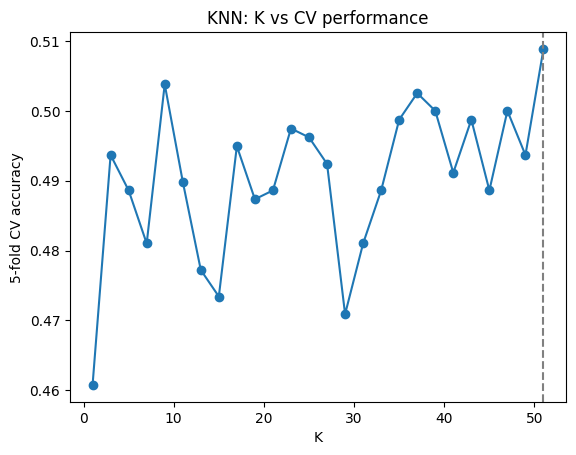

   Model  Accuracy   AUC  TN  FP  FN  TP
Logistic     0.571 0.576  51  45  40  62
     LDA     0.566 0.576  50  46  40  62
     QDA     0.525 0.520  53  43  51  51
     KNN     0.556 0.558  46  50  38  64


In [39]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA
from sklearn.neighbors import KNeighborsClassifier as KNN
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
make = lambda m: Pipeline([("prep", ColumnTransformer([("s", StandardScaler(), num_cols)],
                                                      remainder="passthrough")), ("clf", m)])

# KNN: find best K with CV
ks = list(range(1, 52, 2))
cv_acc = [cross_val_score(make(KNN(k)), X_train, y_train, cv=cv).mean() for k in ks]
best_k = ks[np.argmax(cv_acc)]
print("Best K:", best_k)

plt.plot(ks, cv_acc, marker="o"); plt.axvline(best_k, ls="--", c="gray")
plt.xlabel("K"); plt.ylabel("5-fold CV accuracy"); plt.title("KNN: K vs CV performance"); plt.show()

# Fit all four models and collect results
models = {"Logistic": LogisticRegression(max_iter=1000), "LDA": LDA(), "QDA": QDA(), "KNN": KNN(best_k)}
rows = []
for name, m in models.items():
    p = make(m).fit(X_train, y_train)
    pred, prob = p.predict(X_test), p.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append([name, accuracy_score(y_test, pred), roc_auc_score(y_test, prob), tn, fp, fn, tp])

results = pd.DataFrame(rows, columns=["Model", "Accuracy", "AUC", "TN", "FP", "FN", "TP"])
print(results.round(3).to_string(index=False))

All four classifiers did only a little better than a coin flip, with test accuracy between 52.5% and 57%. Logistic regression and LDA came out on top (about 57% accuracy, 0.576 AUC), KNN was close behind at 55.6%, and QDA was the weakest at 52.5% with an AUC of 0.52, which is basically random guessing. The differences between models are tiny, especially since only having 198 test rows. The KNN graph backs that up since CV accuracy just bounces around 0.46 to 0.51 no matter which K you pick.  

I’d go with logistic regression: it ties for the best score, it’s simple, and it gives interpretable probabilities. The big takeaway is that the features don’t carry much signal for telling kidney disease apart from healthy patients, so no model could do much better.

Part 4  

Evaluate Models

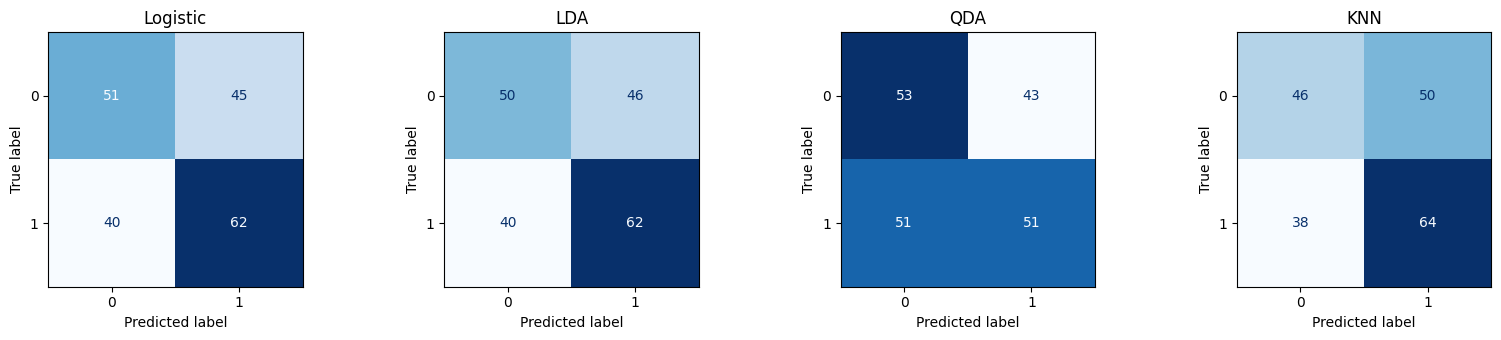

   Model  Accuracy  Precision  Recall  Specificity    F1  ROC-AUC
Logistic     0.571      0.579   0.608        0.531 0.593    0.576
     LDA     0.566      0.574   0.608        0.521 0.590    0.576
     QDA     0.525      0.543   0.500        0.552 0.520    0.520
     KNN     0.556      0.561   0.627        0.479 0.593    0.558


In [40]:
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, f1_score

#classify as kidney disease if predicted probability >= 0.5
THRESH = 0.5

rows = []
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (name, m) in zip(axes, models.items()):
    p = make(m).fit(X_train, y_train)
    prob = p.predict_proba(X_test)[:, 1]
    pred = (prob >= THRESH).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred),
                 recall_score(y_test, pred), tn / (tn + fp), f1_score(y_test, pred),
                 roc_auc_score(y_test, prob)])
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

table = pd.DataFrame(rows, columns=["Model","Accuracy","Precision","Recall","Specificity","F1","ROC-AUC"])
print(table.round(3).to_string(index=False))

I used the standard 0.5 threshold, so anyone with a predicted probability of 0.5 or higher gets labeled kidney disease. The classes are almost perfectly balanced (48.7% vs 51.3%), so there’s no imbalance pushing me to move it. In a real clinic you might lower the threshold to catch more true cases, since missing kidney disease is worse than a false alarm. However, the models barely separate the classes to begin with, so shifting the threshold would just trade recall for specificity without making the model any better.

Part 5  

Reflection

The main thing I found is that none of the models work well. Test accuracy was only 52-57%, barely better than 50-50 chances, even though the features include markers like creatinine and urea. When I compared the two groups, those markers looked almost the same for healthy and kidney disease patients, so the models had very little to learn from. Logistic regression and LDA did best, KNN was close, and QDA was basically guessing (AUC 0.52).

I said in Part 1 that false negatives are the most dangerous mistake (a sick patient gets told they’re fine and loses time for early treatment), thus recall is the most informative metric. KNN had the highest recall (0.627), but it still missed 38 of 102 sick patients, which is far too many for this application. Specificity is the counterweight: KNN’s high recall came with the lowest specificity (0.479), so it flagged about half of healthy patients.  ROC-AUC shows how well a model separates the classes overall, which is why QDA’s 0.52 stands out so clearly. Accuracy is the least useful because it treats a missed case and a false alarm as equally bad, and they’re not.

Part 6  

ROC and AUC

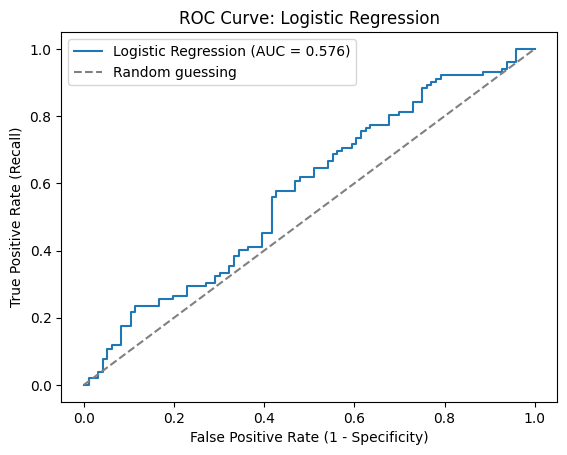

ROC-AUC: 0.576


In [41]:
from sklearn.metrics import roc_curve, roc_auc_score

lr = make(LogisticRegression(max_iter=1000)).fit(X_train, y_train)
prob = lr.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, prob)
auc = roc_auc_score(y_test, prob)

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", c="gray", label="Random guessing")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve: Logistic Regression")
plt.legend(); plt.show()
print("ROC-AUC:", round(auc, 3))

The ROC curve shows how the model does at every possible threshold, not just 0.5. As threshold goes lower, more sick patients are caught (true positive rate goes up), but it also falsely flag more healthy ones (false positive rate goes up), and the curve traces that trade-off. The AUC gives us the number of the chance that the model gives a higher risk score to a randomly picked sick patient than a randomly picked healthy one. An AUC of 1.0 is perfect and 0.5 is random guessing. Ours is 0.576, so the model ranks a sick patient above a healthy one only about 58% of the time, which is barely better than 50/50 chances. The plot shows that since the curve hugs the diagonal line. It aligns with what we saw in the other metrics, which that the features don’t separate the classes well and no threshold would fix that.

Part 7  

Final Analysis

All four did only a little better than guessing. Logistic regression and LDA were the best, getting about 57% of test patients right, and KNN was close behind at 56%. KNN caught the most sick patients (64 of 102) but also wrongly flagged the most healthy ones (50 of 96). QDA was the worst, missing half of the sick patients, and its AUC of 0.52 is basically random guessing. The differences between models are small enough that they could just be luck from a small test set.  

The model I would deploy for this specific application is logistic regression. It ties for the best performance, and it gives a probability for each patient, which lets a doctor see how confident the model is. That matters because missing kidney disease is the worst mistake (a sick patient is told they’re fine and loses time for early treatment), while a false alarm just means a follow-up test. So I’d lower the cutoff below 0.5 to catch more sick patients and accept more false alarms. However, even this model misses 40 of 102 sick patients, thus I would not use it to actually diagnose anyone.  

One limitation is that the predictors barely differ between healthy and sick patients (for example, average creatinine was about 7.4 vs 7.7), so the models had almost nothing to learn from. Some values also don’t look clinically realistic (creatinine up to 15 mg/dL in healthy patients), which raises questions on the data quality.

Additional information and data I would want before using this model in the real world to test the model on data from other hospitals, since this came from one diagnostic center. I would also want to know how the “healthy” and “kidney disease” labels were assigned, because if doctors used these same lab values to decide, the labels should be easy to predict from them, however they are not. Finally, I would want a larger sample.